In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

print("Path to dataset files:", path)

C:\Users\LENOVO\Desktop\Mini_Foresight\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\LENOVO\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1


In [2]:
import os
import pandas as pd

print(os.listdir(path))  

df = pd.read_csv(os.path.join(path, "styles.csv"), on_bad_lines="skip")
print(df.shape)
df.head()

['images', 'myntradataset', 'styles.csv']
(44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [3]:
img_dir = os.path.join(path, "images")

df["img_path"] = df["id"].astype(str).apply(lambda x: os.path.join(img_dir, x + ".jpg"))
df["has_img"] = df["img_path"].apply(os.path.exists)

before = len(df)
df = df[df["has_img"]].reset_index(drop=True)
print(f"Şəkli olmayan atılan sətir: {before - len(df)}")
print(f"Qalan sətir: {len(df)}")

print(df.isna().sum())

Şəkli olmayan atılan sətir: 5
Qalan sətir: 44419
id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
img_path                0
has_img                 0
dtype: int64


In [4]:
import matplotlib.pyplot as plt

counts = df["subCategory"].value_counts()
print("Sinif sayı:", len(counts))
print(counts)

# Faizlə
pct = (counts / len(df) * 100).round(2)
print(pct.head(10))

Sinif sayı: 45
subCategory
Topwear                     15398
Shoes                        7343
Bags                         3055
Bottomwear                   2693
Watches                      2542
Innerwear                    1808
Jewellery                    1079
Eyewear                      1073
Fragrance                    1011
Sandal                        963
Wallets                       933
Flip Flops                    913
Belts                         811
Socks                         698
Lips                          527
Dress                         478
Loungewear and Nightwear      470
Saree                         427
Nails                         329
Makeup                        307
Headwear                      293
Ties                          258
Accessories                   129
Scarves                       118
Cufflinks                     108
Apparel Set                   106
Free Gifts                    104
Stoles                         90
Skin Care            

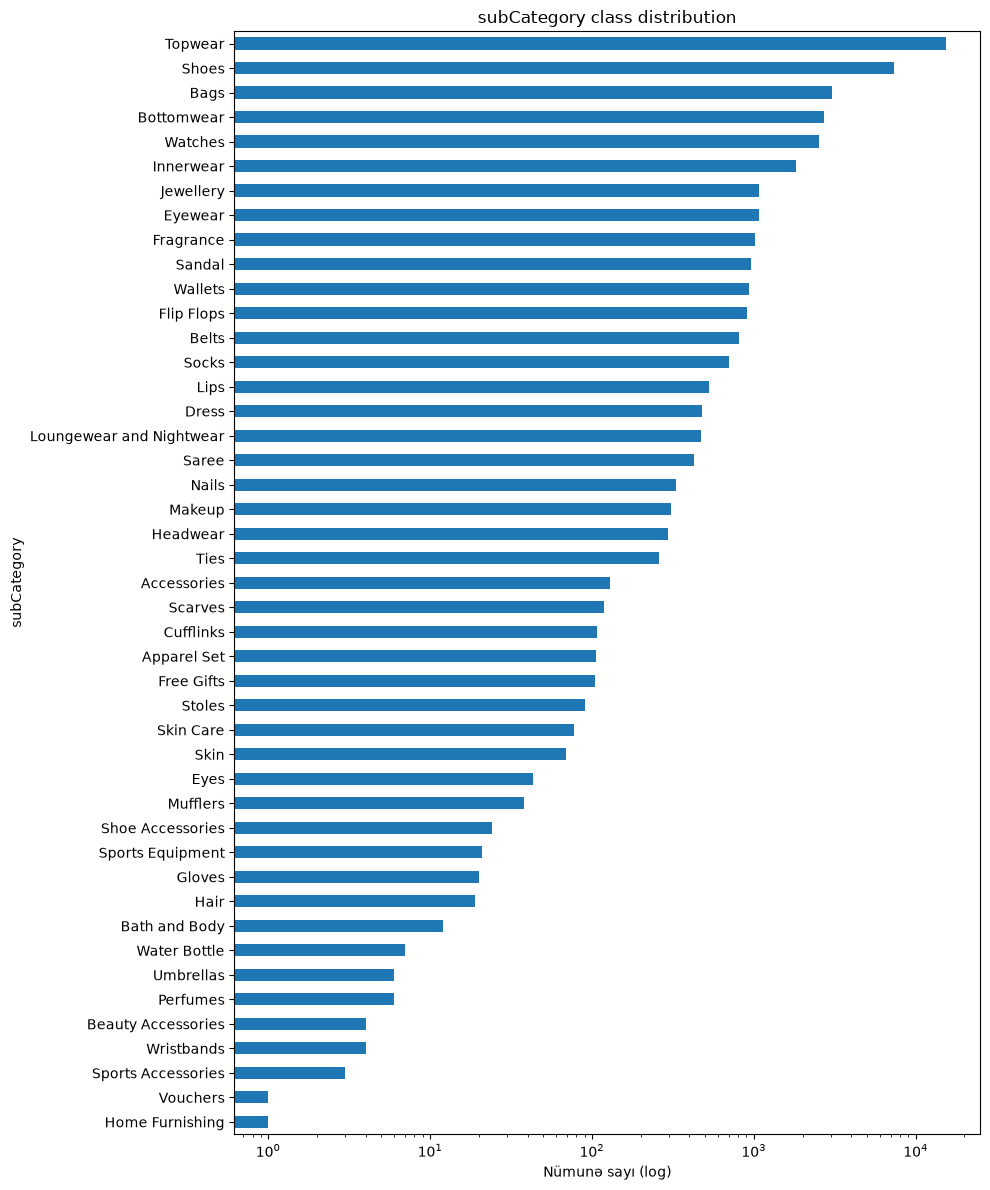

In [5]:
fig, ax = plt.subplots(figsize=(10, 12))
counts.sort_values().plot(kind="barh", ax=ax)
ax.set_xscale("log")   # böyük fərq olduğu üçün log şkala
ax.set_xlabel("Nümunə sayı (log)")
ax.set_title("subCategory class distribution")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [6]:
for t in [5, 10, 20, 50]:
    n = (counts < t).sum()
    print(f"{t}-dən az nümunəsi olan sinif: {n}")

print(counts[counts < 20])

5-dən az nümunəsi olan sinif: 5
10-dən az nümunəsi olan sinif: 8
20-dən az nümunəsi olan sinif: 10
50-dən az nümunəsi olan sinif: 15
subCategory
Hair                  19
Bath and Body         12
Water Bottle           7
Perfumes               6
Umbrellas              6
Beauty Accessories     4
Wristbands             4
Sports Accessories     3
Home Furnishing        1
Vouchers               1
Name: count, dtype: int64


In [7]:
MIN_SAMPLES = 20

counts = df["subCategory"].value_counts()
rare = counts[counts < MIN_SAMPLES].index.tolist()
dropped_rows = df["subCategory"].isin(rare).sum()
print("Atılan siniflər:", rare)
print(f"Atılan sətir: {dropped_rows} ({dropped_rows / len(df) * 100:.2f}%)")

df = df[~df["subCategory"].isin(rare)].reset_index(drop=True)

for c in ["productDisplayName", "baseColour", "usage"]:
    df[c] = df[c].fillna("")

print("Qalan sətir:", len(df), "| Qalan sinif:", df["subCategory"].nunique())

Atılan siniflər: ['Hair', 'Bath and Body', 'Water Bottle', 'Perfumes', 'Umbrellas', 'Beauty Accessories', 'Wristbands', 'Sports Accessories', 'Home Furnishing', 'Vouchers']
Atılan sətir: 63 (0.14%)
Qalan sətir: 44356 | Qalan sinif: 35


In [8]:
from sklearn.preprocessing import LabelEncoder

# Mətn sahələrini birləşdir
df["text"] = (df["productDisplayName"] + " " + df["baseColour"] + " " + df["usage"]).str.strip()

# Sinif adlarını rəqəmlərə çevir (0, 1, 2, ...)
le = LabelEncoder()
df["label"] = le.fit_transform(df["subCategory"])
class_names = list(le.classes_)
num_classes = len(class_names)
print("Sinif sayı:", num_classes)
df[["text", "subCategory", "label"]].head()

Sinif sayı: 35


,text,subCategory,label
0,Turtle Check Men Navy Blue Shirt Navy Blue Casual,Topwear,32
1,Peter England Men Party Blue Jeans Blue Casual,Bottomwear,4
2,Titan Women Silver Watch Silver Casual,Watches,34
3,Manchester United Men Solid Black Track Pants ...,Bottomwear,4
4,Puma Men Grey T-shirt Grey Casual,Topwear,32


In [9]:
import copy, time, pickle, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

In [10]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
MAX_LEN = 32

def tokenize(texts):
    return tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt",
    )

In [11]:
enc = tokenize(["Puma Men Grey T-shirt Grey Casual"])
print(enc["input_ids"].shape)  
print(tokenizer.convert_ids_to_tokens(enc["input_ids"][0][:10]))

torch.Size([1, 32])
['[CLS]', 'pu', '##ma', 'men', 'grey', 't', '-', 'shirt', 'grey', 'casual']


In [12]:
N_SAMPLE = 10000
MIN_CLASS = 100     # CPU subsample üçün minimum sinif ölçüsü
SEED = 42

# 1) Kiçik sinifləri at
cnt = df["subCategory"].value_counts()
small = cnt[cnt < MIN_CLASS].index.tolist()
print("Atılan siniflər:", small, "| sətir:", df["subCategory"].isin(small).sum())
df_base = df[~df["subCategory"].isin(small)].reset_index(drop=True)

# 2) Label-ləri yenidən rəqəmlə (0..K-1 ardıcıl olsun)
le = LabelEncoder()
df_base["label"] = le.fit_transform(df_base["subCategory"])
class_names = list(le.classes_)
num_classes = len(class_names)
print("Sinif sayı:", num_classes)

# 3) Stratified subsample + 70/15/15 split
df_small, _ = train_test_split(df_base, train_size=N_SAMPLE, stratify=df_base["label"], random_state=SEED)
train_df, temp_df = train_test_split(df_small, test_size=0.30, stratify=df_small["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Ən az nümunəli sinif (test):", test_df["label"].value_counts().min())

train_df.to_csv("train_small.csv", index=False)
val_df.to_csv("val_small.csv", index=False)
test_df.to_csv("test_small.csv", index=False)

Atılan siniflər: ['Stoles', 'Skin Care', 'Skin', 'Eyes', 'Mufflers', 'Shoe Accessories', 'Sports Equipment', 'Gloves'] | sətir: 382
Sinif sayı: 27
Train: 7000 | Val: 1500 | Test: 1500
Ən az nümunəli sinif (test): 3


In [13]:
lengths = [len(tokenizer.encode(t)) for t in train_df["text"]]
import numpy as np
print("Orta:", np.mean(lengths))
print("Maksimum:", max(lengths))
print("95-ci percentil:", np.percentile(lengths, 95))
print("32-dən uzun olanlar:", (np.array(lengths) > 32).mean() * 100, "%")

Orta: 12.118142857142857
Maksimum: 33
95-ci percentil: 17.0
32-dən uzun olanlar: 0.014285714285714287 %


In [14]:
IMG_SIZE = 112
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [15]:
import re

all_df = pd.concat([train_df, val_df, test_df])
vocab = set()
for col in ["masterCategory", "subCategory", "articleType"]:
    if col in all_df.columns:
        for v in all_df[col].dropna().unique():
            for w in re.findall(r"[A-Za-z]+", v):
                w = w.lower()
                if len(w) >= 3:
                    vocab.add(w[:-1] if w.endswith("s") else w)
vocab |= {"deo", "slipper", "heel", "tee", "watch", "tshirt"}

pat = re.compile(r"\b(" + "|".join(sorted(map(re.escape, vocab), key=len, reverse=True)) + r")(?:e?s)?\b", re.I)

def clean_name(s):
    s = re.sub(r"\bt-?shirts?\b", "", s, flags=re.I)
    return re.sub(r"\s+", " ", pat.sub("", s)).strip()

def make_text(df):
    return (df["productDisplayName"].apply(clean_name) + " " + df["baseColour"] + " " + df["usage"]).str.strip()

for i in range(8):
    print(test_df["productDisplayName"].iloc[i], "->", clean_name(test_df["productDisplayName"].iloc[i]))

Inc 5 Women Casual Gold Heels -> Inc 5 Women Gold
United Colors of Benetton Kids Boys Pink Printed T-shirt -> United Colors of Benetton Kids Boys Pink Printed
Spykar Men Ranger Blue-White Stripes Shirts -> Spykar Men Ranger Blue-White Stripes
Skechers Men Regions Black Shoe -> Skechers Men Regions Black
Jacques M Women Rich 'N Famous Deo -> Jacques M Women Rich 'N Famous
Flying Machine Men White Shirt -> Flying Machine Men White
United Colors of Benetton Men Check Green Shirts -> United Colors of Benetton Men Check Green
Nike Women Wmns Dou Black Sports Shoes -> Nike Women Wmns Dou Black


In [16]:
for d in (train_df, val_df, test_df):
    d["text"] = make_text(d)

print(train_df["text"].head(10).tolist())

['Hanes Men ComfortSoft Pack of 2 Waistband Hip Grey Casual', 'Nike Men Field Trainer Textile Grey Grey Sports', 'Allen Solly Men Navy Blue Navy Blue Formal', 'Puma Men V.11 Cat Midnight Navy Navy Blue Sports', 'Belmonte Men Thread Black Black Casual', 'Indigo Nation Men Striped Black Black Casual', 'Lino Perros Men Purple Purple Formal', 'Revv Men Steel Steel Casual', 'Police Men Wings Silver Silver Casual', 'Clarks Women Black Handcrafted Leather Black Casual']


In [17]:
class ProductDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["img_path"].tolist()
        self.labels = df["label"].tolist()
        self.transform = transform
        enc = tokenize(df["text"])
        self.input_ids = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        img = self.transform(img)
        return {
            "image": img,
            "input_ids": self.input_ids[i],
            "attention_mask": self.attention_mask[i],
            "label": torch.tensor(self.labels[i], dtype=torch.long),
        }

BATCH_SIZE = 64

train_ds = ProductDataset(train_df, train_tf)
val_ds   = ProductDataset(val_df, eval_tf)
test_ds  = ProductDataset(test_df, eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

batch = next(iter(train_loader))
print(batch["image"].shape)           
print(batch["input_ids"].shape)     
print(batch["attention_mask"].shape)  
print(batch["label"].shape)           

torch.Size([64, 3, 112, 112])
torch.Size([64, 32])
torch.Size([64, 32])
torch.Size([64])


In [18]:
import torch.nn as nn
from torchvision import models
from sklearn.metrics import f1_score, accuracy_score
import copy, time

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---- Üç model üçün EYNİ ayarlar ----
EPOCHS = 5
LR = 1e-3
criterion = nn.CrossEntropyLoss()

# ---- Model A: yalnız şəkil ----
class ImageModel(nn.Module):
    def __init__(self, num_classes, freeze=True):
        super().__init__()
        self.freeze = freeze
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        if freeze:
            for p in self.backbone.parameters():
                p.requires_grad = False
        self.backbone.fc = nn.Linear(512, num_classes)   # yeni head, həmişə təlim olunur

    def train(self, mode=True):
        super().train(mode)
        if self.freeze:                      # dondurulmuş qatlarda BatchNorm də dəyişməsin
            for name, m in self.backbone.named_children():
                if name != "fc":
                    m.eval()
        return self

    def forward(self, batch):
        return self.backbone(batch["image"])

# ---- Qiymətləndirmə ----
def evaluate(model, loader):
    model.eval()
    preds, labels, total_loss = [], [], 0.0
    with torch.no_grad():
        for b in loader:
            b = {k: v.to(device) for k, v in b.items()}
            out = model(b)
            total_loss += criterion(out, b["label"]).item() * len(b["label"])
            preds += out.argmax(1).cpu().tolist()
            labels += b["label"].cpu().tolist()
    return {
        "loss": total_loss / len(labels),
        "acc": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
        "weighted_f1": f1_score(labels, preds, average="weighted"),
        "preds": preds, "labels": labels,
    }

# ---- Təlim ----
def train_model(model, name):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=LR)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1, best_state = -1, None

    for epoch in range(EPOCHS):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for b in train_loader:
            b = {k: v.to(device) for k, v in b.items()}
            optimizer.zero_grad()
            loss = criterion(model(b), b["label"])
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(b["label"])
            n += len(b["label"])

        val = evaluate(model, val_loader)
        history["train_loss"].append(run_loss / n)
        history["val_loss"].append(val["loss"])
        history["val_macro_f1"].append(val["macro_f1"])
        print(f"[{name}] epoch {epoch+1}/{EPOCHS} | train_loss {run_loss/n:.4f} | "
              f"val_loss {val['loss']:.4f} | val_macro_f1 {val['macro_f1']:.4f} | {time.time()-t0:.0f}s")

        if val["macro_f1"] > best_f1:
            best_f1, best_state = val["macro_f1"], copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test = evaluate(model, test_loader)      # test yalnız sonda, 1 dəfə
    print(f"[{name}] TEST | acc {test['acc']:.4f} | macro_f1 {test['macro_f1']:.4f} | "
          f"weighted_f1 {test['weighted_f1']:.4f}")
    return model, history, test

# ---- Model A-nı təlim et ----
results, histories = {}, {}
model_a = ImageModel(num_classes, freeze=True)
model_a, histories["image"], results["image"] = train_model(model_a, "image")

Device: cpu
[image] epoch 1/5 | train_loss 1.2800 | val_loss 0.7493 | val_macro_f1 0.4581 | 110s
[image] epoch 2/5 | train_loss 0.6950 | val_loss 0.5951 | val_macro_f1 0.5375 | 102s
[image] epoch 3/5 | train_loss 0.5755 | val_loss 0.5234 | val_macro_f1 0.5772 | 99s
[image] epoch 4/5 | train_loss 0.4993 | val_loss 0.4867 | val_macro_f1 0.6094 | 89s
[image] epoch 5/5 | train_loss 0.4641 | val_loss 0.4492 | val_macro_f1 0.6138 | 89s
[image] TEST | acc 0.8773 | macro_f1 0.6622 | weighted_f1 0.8630


In [19]:
from transformers import AutoModel

bert = AutoModel.from_pretrained("distilbert-base-uncased").to(device).eval()

@torch.no_grad()
def embed(input_ids, attention_mask, bs=128):
    out = []
    for i in range(0, len(input_ids), bs):
        ids = input_ids[i:i+bs].to(device)
        m = attention_mask[i:i+bs].to(device)
        h = bert(input_ids=ids, attention_mask=m).last_hidden_state   # [bs, 32, 768]
        mm = m.unsqueeze(-1).float()
        out.append(((h * mm).sum(1) / mm.sum(1)).cpu())               # mean pooling -> [bs, 768]
    return torch.cat(out)

t0 = time.time()
emb_train = embed(train_ds.input_ids, train_ds.attention_mask)
emb_val   = embed(val_ds.input_ids,   val_ds.attention_mask)
emb_test  = embed(test_ds.input_ids,  test_ds.attention_mask)
print(emb_train.shape, emb_val.shape, emb_test.shape, f"{time.time()-t0:.0f}s")

torch.save({"train": emb_train, "val": emb_val, "test": emb_test}, "text_emb.pt")

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 628.33it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


torch.Size([7000, 768]) torch.Size([1500, 768]) torch.Size([1500, 768]) 193s


In [20]:
from torch.utils.data import Dataset, DataLoader

class EmbDataset(Dataset):
    def __init__(self, emb, labels):
        self.emb, self.labels = emb, torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return {"emb": self.emb[i], "label": self.labels[i]}

et_loader = DataLoader(EmbDataset(emb_train, train_df["label"].tolist()), batch_size=BATCH_SIZE, shuffle=True)
ev_loader = DataLoader(EmbDataset(emb_val,   val_df["label"].tolist()),   batch_size=BATCH_SIZE)
es_loader = DataLoader(EmbDataset(emb_test,  test_df["label"].tolist()),  batch_size=BATCH_SIZE)

class TextModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.fc = nn.Linear(768, num_classes)
    def forward(self, batch):
        return self.fc(batch["emb"])

def train_model(model, name, tr=None, va=None, te=None):
    tr, va, te = tr or train_loader, va or val_loader, te or test_loader
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=LR)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1, best_state = -1, None

    for epoch in range(EPOCHS):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for b in tr:
            b = {k: v.to(device) for k, v in b.items()}
            optimizer.zero_grad()
            loss = criterion(model(b), b["label"])
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(b["label"])
            n += len(b["label"])

        val = evaluate(model, va)
        history["train_loss"].append(run_loss / n)
        history["val_loss"].append(val["loss"])
        history["val_macro_f1"].append(val["macro_f1"])
        print(f"[{name}] epoch {epoch+1}/{EPOCHS} | train_loss {run_loss/n:.4f} | "
              f"val_loss {val['loss']:.4f} | val_macro_f1 {val['macro_f1']:.4f} | {time.time()-t0:.0f}s")
        if val["macro_f1"] > best_f1:
            best_f1, best_state = val["macro_f1"], copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test = evaluate(model, te)
    print(f"[{name}] TEST | acc {test['acc']:.4f} | macro_f1 {test['macro_f1']:.4f} | "
          f"weighted_f1 {test['weighted_f1']:.4f}")
    return model, history, test

model_b = TextModel(num_classes)
model_b, histories["text"], results["text"] = train_model(model_b, "text", et_loader, ev_loader, es_loader)

[text] epoch 1/5 | train_loss 2.1703 | val_loss 1.8852 | val_macro_f1 0.1009 | 1s
[text] epoch 2/5 | train_loss 1.7592 | val_loss 1.6460 | val_macro_f1 0.1582 | 0s
[text] epoch 3/5 | train_loss 1.5674 | val_loss 1.5095 | val_macro_f1 0.2043 | 0s
[text] epoch 4/5 | train_loss 1.4427 | val_loss 1.4197 | val_macro_f1 0.2760 | 0s
[text] epoch 5/5 | train_loss 1.3561 | val_loss 1.3505 | val_macro_f1 0.3298 | 0s
[text] TEST | acc 0.6007 | macro_f1 0.2960 | weighted_f1 0.5362


In [21]:
results["text_lr1e-3"] = results["text"]
histories["text_lr1e-3"] = histories["text"]

In [22]:
LR_BACKUP = LR
LR = 1e-2          
model_b = TextModel(num_classes)
model_b, histories["text"], results["text"] = train_model(model_b, "text", et_loader, ev_loader, es_loader)
LR = LR_BACKUP

[text] epoch 1/5 | train_loss 1.6193 | val_loss 1.2711 | val_macro_f1 0.4062 | 1s
[text] epoch 2/5 | train_loss 1.1244 | val_loss 1.1134 | val_macro_f1 0.4981 | 0s
[text] epoch 3/5 | train_loss 0.9849 | val_loss 1.0498 | val_macro_f1 0.5293 | 0s
[text] epoch 4/5 | train_loss 0.9133 | val_loss 0.9992 | val_macro_f1 0.5588 | 0s
[text] epoch 5/5 | train_loss 0.8641 | val_loss 1.0249 | val_macro_f1 0.5618 | 0s
[text] TEST | acc 0.6967 | macro_f1 0.5394 | weighted_f1 0.6584


In [23]:
results["text_lr1e-2"] = results["text"]
histories["text_lr1e-2"] = histories["text"]

In [24]:
results["image_lr1e-3"] = results["image"]
histories["image_lr1e-3"] = histories["image"]

LR = 1e-2
model_a = ImageModel(num_classes, freeze=True)
model_a, histories["image"], results["image"] = train_model(model_a, "image")
LR = LR_BACKUP

[image] epoch 1/5 | train_loss 1.0378 | val_loss 0.6786 | val_macro_f1 0.5772 | 98s
[image] epoch 2/5 | train_loss 0.5901 | val_loss 0.6947 | val_macro_f1 0.5834 | 99s
[image] epoch 3/5 | train_loss 0.5533 | val_loss 0.6663 | val_macro_f1 0.5980 | 88s
[image] epoch 4/5 | train_loss 0.5866 | val_loss 0.6754 | val_macro_f1 0.6595 | 80s
[image] epoch 5/5 | train_loss 0.5518 | val_loss 0.6433 | val_macro_f1 0.6618 | 77s
[image] TEST | acc 0.8700 | macro_f1 0.6905 | weighted_f1 0.8657


In [25]:
results["image_lr1e-2"] = results["image"]
histories["image_lr1e-2"] = histories["image"]

In [26]:
torch.manual_seed(42)

# --- train_model: lr arqumenti ilə, qlobal LR-ə toxunmur ---
def train_model(model, name, tr=None, va=None, te=None, lr=None):
    tr, va, te = tr or train_loader, va or val_loader, te or test_loader
    lr = lr or LR
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1, best_state = -1, None

    for epoch in range(EPOCHS):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for b in tr:
            b = {k: v.to(device) for k, v in b.items()}
            optimizer.zero_grad()
            loss = criterion(model(b), b["label"])
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(b["label"])
            n += len(b["label"])
        val = evaluate(model, va)
        history["train_loss"].append(run_loss / n)
        history["val_loss"].append(val["loss"])
        history["val_macro_f1"].append(val["macro_f1"])
        print(f"[{name}] epoch {epoch+1}/{EPOCHS} | train_loss {run_loss/n:.4f} | "
              f"val_loss {val['loss']:.4f} | val_macro_f1 {val['macro_f1']:.4f} | {time.time()-t0:.0f}s")
        if val["macro_f1"] > best_f1:
            best_f1, best_state = val["macro_f1"], copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    test = evaluate(model, te)
    print(f"[{name}] TEST | acc {test['acc']:.4f} | macro_f1 {test['macro_f1']:.4f} | "
          f"weighted_f1 {test['weighted_f1']:.4f}")
    return model, history, test, best_f1

# --- Dataset: şəkil (augmentation ilə) + hazır mətn embedding ---
class ProductDatasetEmb(ProductDataset):
    def __init__(self, df, transform, emb):
        super().__init__(df, transform)
        self.emb = emb
    def __getitem__(self, i):
        d = super().__getitem__(i)
        d["emb"] = self.emb[i]
        return d

fa_train = DataLoader(ProductDatasetEmb(train_df, train_tf, emb_train), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
fa_val   = DataLoader(ProductDatasetEmb(val_df,   eval_tf,  emb_val),   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
fa_test  = DataLoader(ProductDatasetEmb(test_df,  eval_tf,  emb_test),  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# --- Fusion modeli: late fusion by concatenation ---
class FusionModelLive(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.resnet.fc = nn.Identity()
        for p in self.resnet.parameters():
            p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(512 + 768, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def train(self, mode=True):
        super().train(mode)
        self.resnet.eval()      # dondurulmuş: BatchNorm dəyişməsin
        return self

    def forward(self, batch):
        with torch.no_grad():
            f = self.resnet(batch["image"])
        return self.head(torch.cat([f, batch["emb"]], dim=1))

# --- LR namizədləri, seçim VAL üzrə ---
fusion_runs = {}
for lr in [1e-3, 1e-2]:
    torch.manual_seed(42)
    m = FusionModelLive(num_classes)
    m, h, r, bf = train_model(m, f"fusion lr={lr}", fa_train, fa_val, fa_test, lr=lr)
    fusion_runs[lr] = (m, h, r, bf)
    print(f"--> lr={lr}: best val macro F1 = {bf:.4f}\n")

best_lr = max(fusion_runs, key=lambda k: fusion_runs[k][3])
print("Seçilən LR (val üzrə):", best_lr)
model_c, histories["fusion"], results["fusion"], _ = fusion_runs[best_lr]

[fusion lr=0.001] epoch 1/5 | train_loss 1.1320 | val_loss 0.5644 | val_macro_f1 0.4879 | 102s
[fusion lr=0.001] epoch 2/5 | train_loss 0.5624 | val_loss 0.4263 | val_macro_f1 0.5887 | 96s
[fusion lr=0.001] epoch 3/5 | train_loss 0.4170 | val_loss 0.3392 | val_macro_f1 0.6488 | 88s
[fusion lr=0.001] epoch 4/5 | train_loss 0.3639 | val_loss 0.2963 | val_macro_f1 0.7371 | 92s
[fusion lr=0.001] epoch 5/5 | train_loss 0.3188 | val_loss 0.2881 | val_macro_f1 0.7351 | 99s
[fusion lr=0.001] TEST | acc 0.9140 | macro_f1 0.7373 | weighted_f1 0.9041
--> lr=0.001: best val macro F1 = 0.7371

[fusion lr=0.01] epoch 1/5 | train_loss 1.6372 | val_loss 0.7256 | val_macro_f1 0.3872 | 97s
[fusion lr=0.01] epoch 2/5 | train_loss 0.8699 | val_loss 0.6510 | val_macro_f1 0.3971 | 111s
[fusion lr=0.01] epoch 3/5 | train_loss 0.7765 | val_loss 0.6172 | val_macro_f1 0.4099 | 142s
[fusion lr=0.01] epoch 4/5 | train_loss 0.7613 | val_loss 0.5456 | val_macro_f1 0.4727 | 101s
[fusion lr=0.01] epoch 5/5 | train_lo

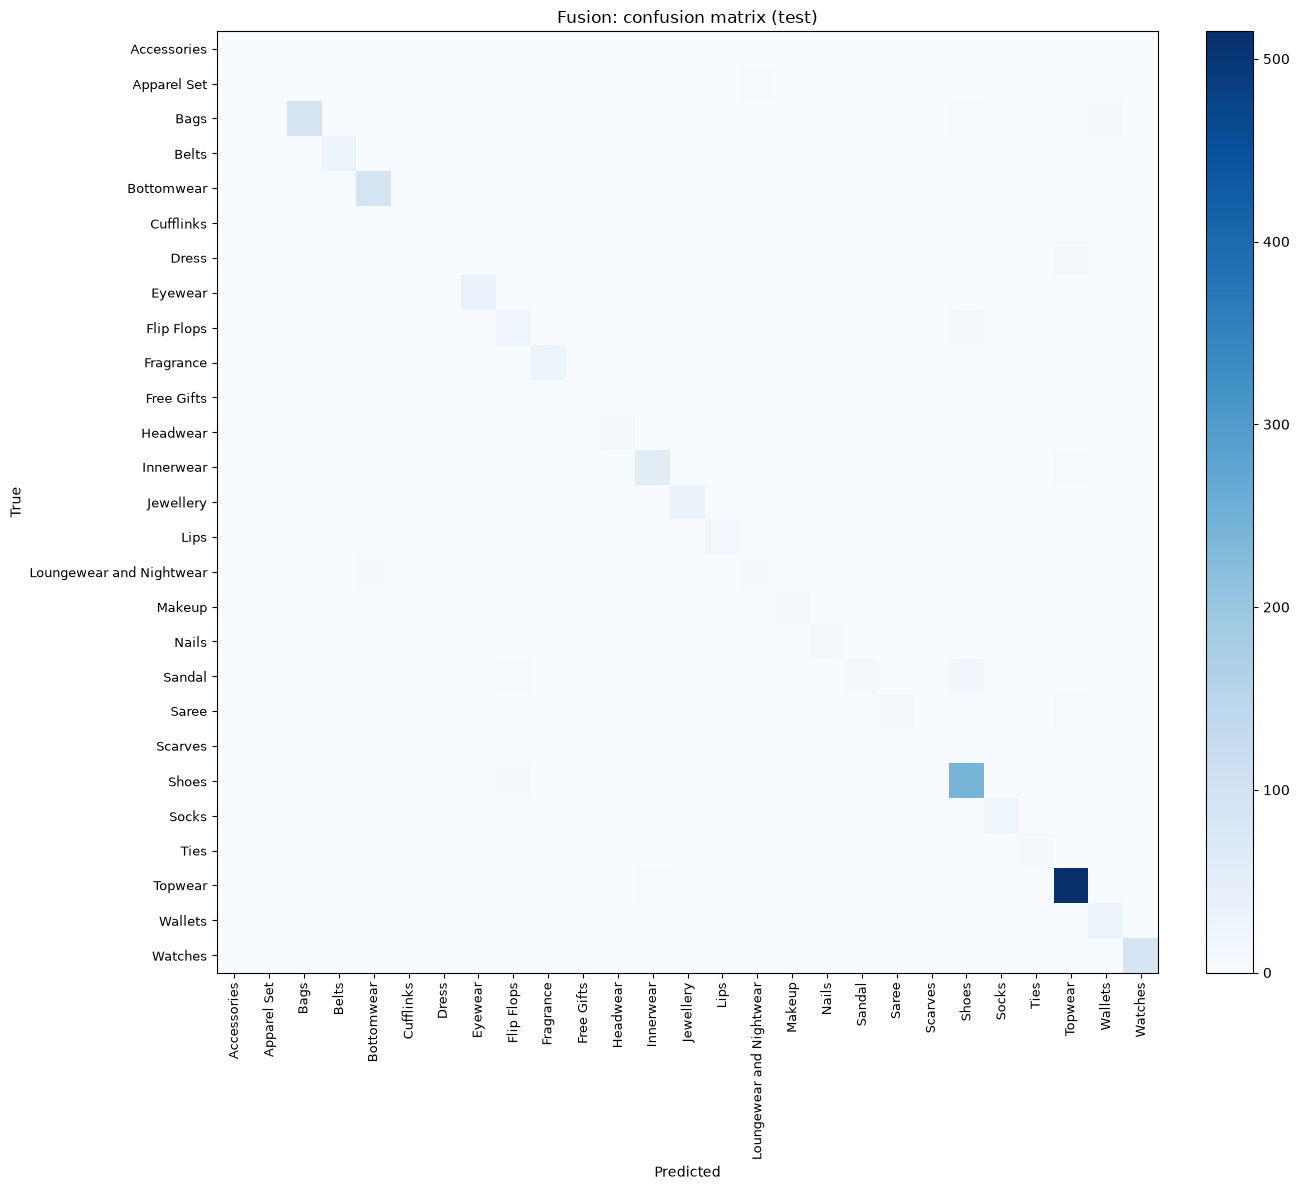

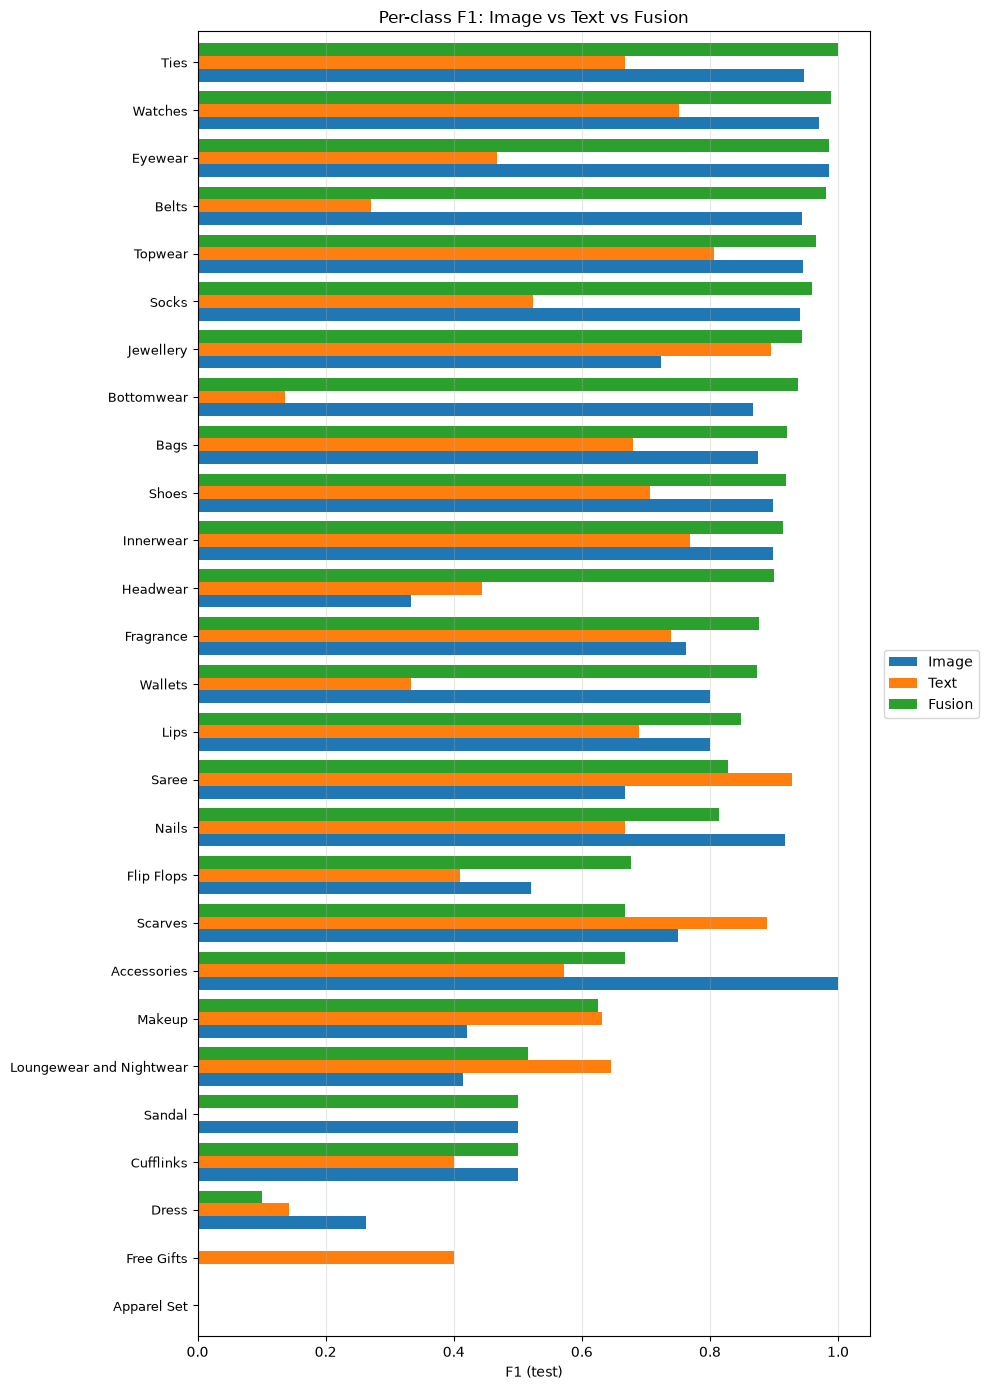

Fusion-un ən pis 3 sinfi:
                Image      Text  Fusion  support
Apparel Set  0.000000  0.000000     0.0        3
Free Gifts   0.000000  0.400000     0.0        3
Dress        0.263158  0.142857     0.1       17

Fusion - Text: fusion ən çox KÖMƏK etdi:
Bottomwear    0.800920
Belts         0.711548
Wallets       0.539906
Eyewear       0.517830
Sandal        0.500000
dtype: float64

Fusion - Text: fusion ən çox ZƏRƏR verdi:
Free Gifts                 -0.400000
Scarves                    -0.222222
Loungewear and Nightwear   -0.129032
Saree                      -0.100985
Dress                      -0.042857
dtype: float64


In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score

# --- Confusion matrix (fusion) ---
r = results["fusion"]
cm = confusion_matrix(r["labels"], r["preds"], labels=range(num_classes))

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(num_classes)); ax.set_yticks(range(num_classes))
ax.set_xticklabels(class_names, rotation=90, fontsize=9)
ax.set_yticklabels(class_names, fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Fusion: confusion matrix (test)")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Per-class F1 (3 model) ---
f1 = pd.DataFrame({
    n: f1_score(results[k]["labels"], results[k]["preds"], average=None, labels=range(num_classes))
    for k, n in [("image", "Image"), ("text", "Text"), ("fusion", "Fusion")]
}, index=class_names)
f1["support"] = np.bincount(results["fusion"]["labels"], minlength=num_classes)

plot_df = f1.drop(columns="support").sort_values("Fusion")

fig, ax = plt.subplots(figsize=(10, 14))
plot_df.plot(kind="barh", ax=ax, width=0.8)
ax.set_xlabel("F1 (test)")
ax.set_title("Per-class F1: Image vs Text vs Fusion")
ax.set_xlim(0, 1.05)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig("per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

print("Fusion-un ən pis 3 sinfi:")
print(f1.sort_values("Fusion").head(3))

d = f1["Fusion"] - f1["Text"]
print("\nFusion - Text: fusion ən çox KÖMƏK etdi:")
print(d.sort_values(ascending=False).head(5))
print("\nFusion - Text: fusion ən çox ZƏRƏR verdi:")
print(d.sort_values().head(5))

               Accuracy  Macro F1  Weighted F1
Model                                         
A: Image-only    0.8700    0.6905       0.8657
B: Text-only     0.6967    0.5394       0.6584
C: Fusion        0.9140    0.7373       0.9041


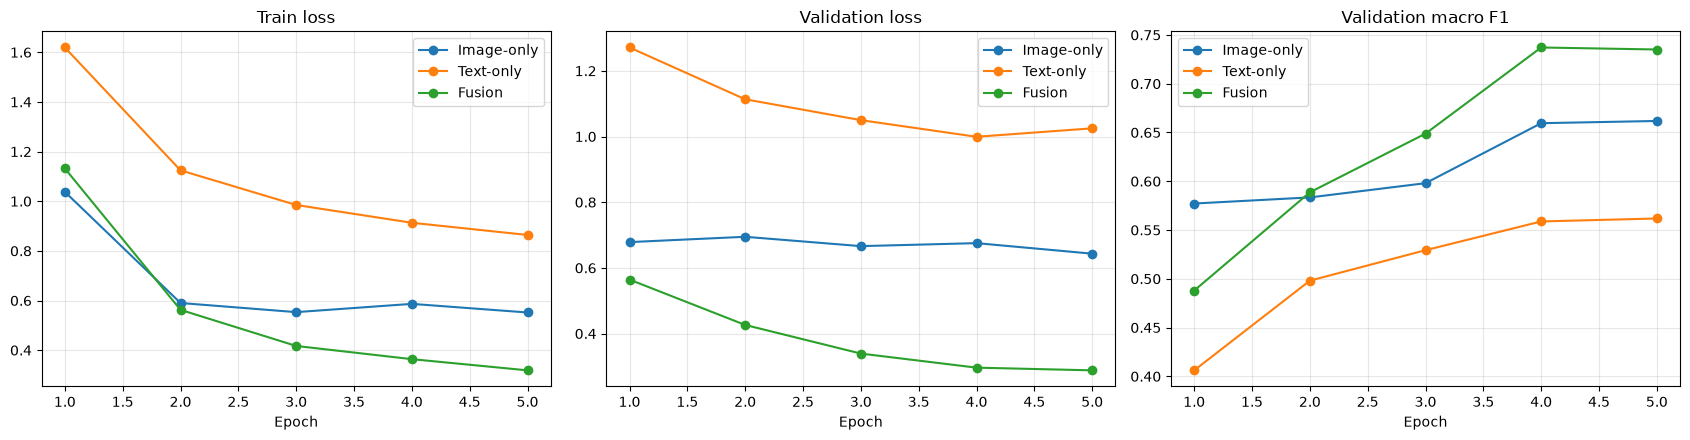

In [28]:
rows = []
for key, title in [("image", "A: Image-only"), ("text", "B: Text-only"), ("fusion", "C: Fusion")]:
    r = results[key]
    rows.append({"Model": title, "Accuracy": r["acc"], "Macro F1": r["macro_f1"], "Weighted F1": r["weighted_f1"]})
comp = pd.DataFrame(rows).set_index("Model").round(4)
print(comp)
comp.to_csv("comparison_table.csv")

names = {"image": "Image-only", "text": "Text-only", "fusion": "Fusion"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, n in names.items():
    ep = range(1, len(histories[k]["train_loss"]) + 1)
    axes[0].plot(ep, histories[k]["train_loss"], marker="o", label=n)
    axes[1].plot(ep, histories[k]["val_loss"], marker="o", label=n)
    axes[2].plot(ep, histories[k]["val_macro_f1"], marker="o", label=n)
for ax, t in zip(axes, ["Train loss", "Validation loss", "Validation macro F1"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Fusion-un səhv etdiyi nümunə sayı: 129 / 1500
Fusion səhv, text düzgün: 38 | hər ikisi səhv: 91 | fusion düzgün, text səhv: 364
#1022 | clean='Colorbar Star Shine Mocha Late 017 Brown Casual' | orig='Colorbar Star Shine Mocha Late Lip Gloss 017' | articleType=Lip Gloss | true=Lips | fusion=Nails | text=Lips | image=Fragrance
#1218 | clean='Nike Women Black Sling Black Casual' | orig='Nike Women Black Sling Bag' | articleType=Handbags | true=Bags | fusion=Shoes | text=Bags | image=Bags
#843 | clean='iPanema Women Ritmos Black Black Casual' | orig='iPanema Women Ritmos Black Heels' | articleType=Heels | true=Shoes | fusion=Flip Flops | text=Shoes | image=Sandal
#287 | clean='Hanes Men Grey Contrast piping Grey Casual' | orig='Hanes Men Grey Contrast piping Lounge Pants' | articleType=Lounge Pants | true=Loungewear and Nightwear | fusion=Bottomwear | text=Innerwear | image=Bottomwear
#992 | clean='Sepia Women Printed Red Red Casual' | orig='Sepia Women Printed Red Dress' | articleType=Dre

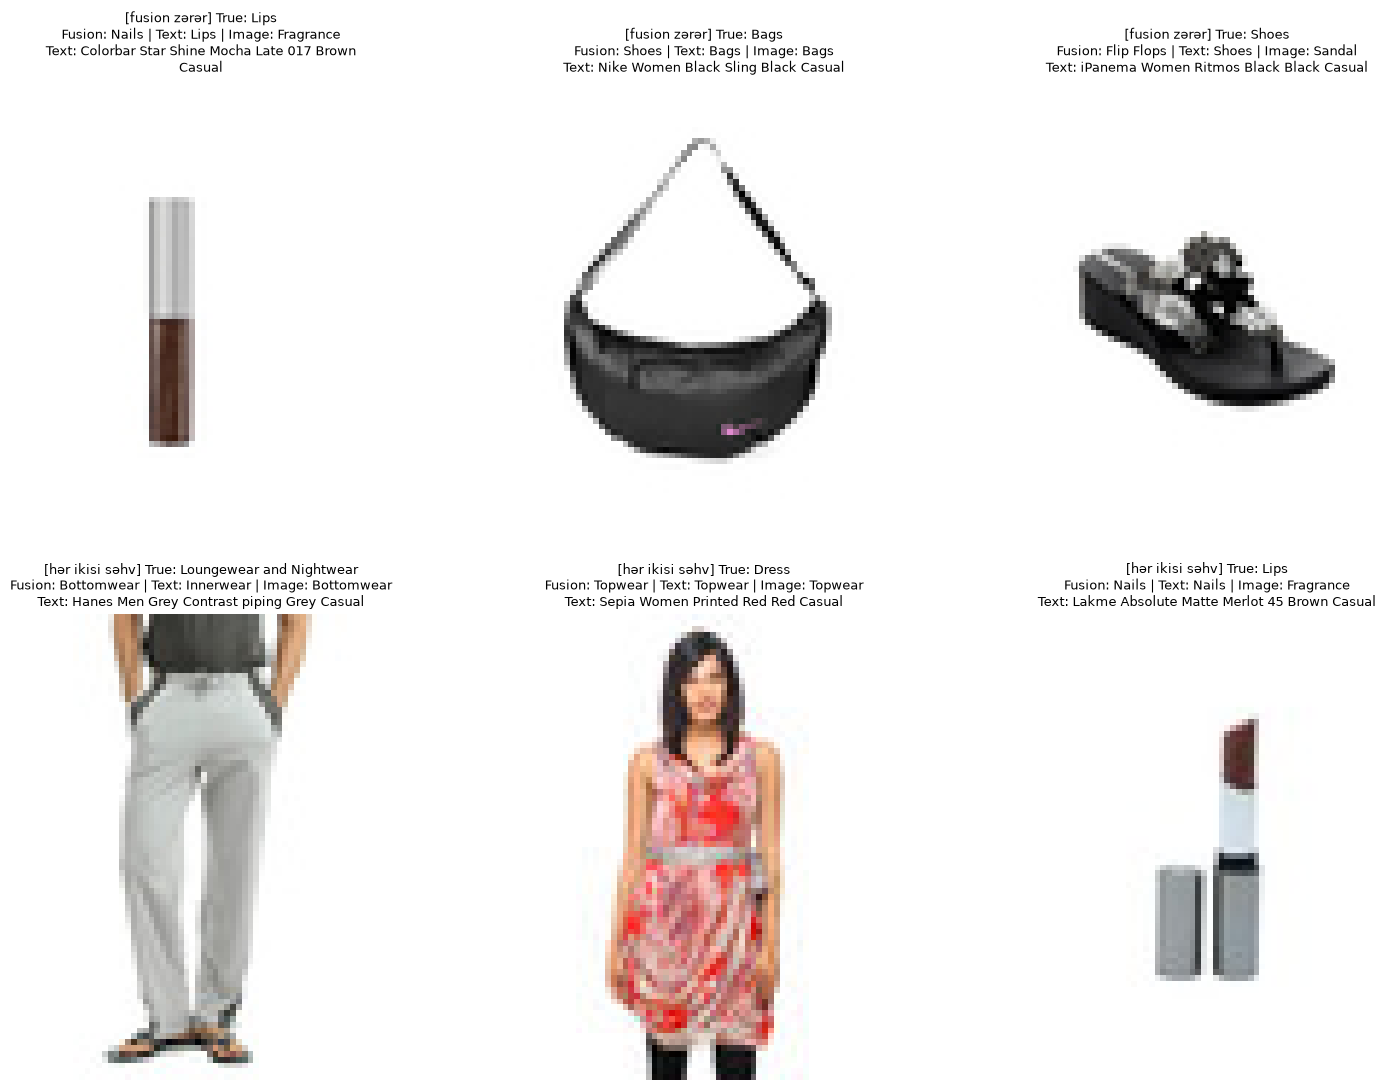

In [29]:
import textwrap

rng = np.random.RandomState(0)

fus, txt, img = results["fusion"], results["text"], results["image"]

wrong = [i for i, (p, l) in enumerate(zip(fus["preds"], fus["labels"])) if p != l]
print("Fusion-un səhv etdiyi nümunə sayı:", len(wrong), "/", len(test_df))

# fusion səhv, text düzgün (fusion-un zərər verdiyi hallar)
hurt = [i for i in wrong if txt["preds"][i] == txt["labels"][i]]
# hər ikisi səhv
both = [i for i in wrong if txt["preds"][i] != txt["labels"][i]]
# fusion düzgün, text səhv (fusion-un kömək etdiyi hallar)
helped = sum(1 for i in range(len(test_df))
             if fus["preds"][i] == fus["labels"][i] and txt["preds"][i] != txt["labels"][i])
print("Fusion səhv, text düzgün:", len(hurt), "| hər ikisi səhv:", len(both),
      "| fusion düzgün, text səhv:", helped)

def sample(a, k):
    return list(rng.choice(a, min(k, len(a)), replace=False)) if len(a) else []

pick = sample(hurt, 3) + sample(both, 3)
# 6-dan az çıxsa, qalan səhvlərdən tamamla
if len(pick) < 6:
    rest = [i for i in wrong if i not in pick]
    pick += sample(rest, 6 - len(pick))
pick = [int(i) for i in pick]

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax in axes.ravel():
    ax.axis("off")

for ax, i in zip(axes.ravel(), pick):
    row = test_df.iloc[i]
    ax.imshow(Image.open(row["img_path"]).convert("RGB"))
    tag = "fusion zərər" if i in hurt else "hər ikisi səhv"
    title = (f"[{tag}] True: {class_names[fus['labels'][i]]}\n"
             f"Fusion: {class_names[fus['preds'][i]]} | "
             f"Text: {class_names[txt['preds'][i]]} | "
             f"Image: {class_names[img['preds'][i]]}\n"
             + textwrap.fill("Text: " + row["text"], 50))
    ax.set_title(title, fontsize=9)
    print(f"#{i} | clean='{row['text']}' | orig='{row['productDisplayName']}' | "
          f"articleType={row['articleType']} | true={class_names[fus['labels'][i]]} | "
          f"fusion={class_names[fus['preds'][i]]} | text={class_names[txt['preds'][i]]} | "
          f"image={class_names[img['preds'][i]]}")

plt.tight_layout()
plt.savefig("misclassified_grid.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
print(train_df[train_df["text"].str.contains("Nike")]["subCategory"].value_counts())
print(train_df[train_df["text"].str.contains("iPanema")]["subCategory"].value_counts())
print(train_df[train_df["text"].str.contains("Lakme")]["subCategory"].value_counts())

subCategory
Shoes         122
Topwear       113
Bottomwear     32
Bags           28
Fragrance      14
Socks          12
Flip Flops     10
Headwear        8
Sandal          3
Name: count, dtype: int64
subCategory
Flip Flops    16
Shoes          5
Name: count, dtype: int64
subCategory
Makeup    12
Nails     10
Lips      10
Name: count, dtype: int64
